# Kanak — Finish the complaint-analysis project
A short companion notebook • Run each cell from top to bottom.

**Goal:** describe the three topic groups, compare company responses, check missing dispute data, and save a small results package. No new model training is needed.

## Before opening this notebook
In your **original notebook**, after creating `analysis_df` from `topics_refined`, run:
```python
from google.colab import files
analysis_df.to_csv("complaints_with_topics.csv", index=False)
files.download("complaints_with_topics.csv")
```
Then open this companion in Colab and upload that CSV below. A new notebook does not share variables with the original one.

The CSV must contain `topic` and `company_response_to_consumer`. Keep the topic numbers: the topic names discussed earlier were provisional.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Upload the CSV downloaded from the original notebook.
from google.colab import files
uploaded = files.upload()
csv_names = [name for name in uploaded if name.lower().endswith('.csv')]
if len(csv_names) != 1:
    raise ValueError('Upload exactly one CSV: complaints_with_topics.csv')
data = pd.read_csv(csv_names[0])
required = {'topic', 'company_response_to_consumer'}
if not required.issubset(data.columns):
    raise ValueError(f'Missing columns: {required - set(data.columns)}')
if data.empty or data['topic'].isna().any():
    raise ValueError('The file must contain complaints with a topic on every row.')
print(f'Loaded {len(data)} complaints.')
display(data[['topic', 'company_response_to_consumer']].head())

Saving complaints_with_topics.csv to complaints_with_topics.csv
Loaded 200 complaints.


,topic,company_response_to_consumer
0,0,Closed with non-monetary relief
1,1,Closed with non-monetary relief
2,2,Closed with explanation
3,2,Closed with explanation
4,2,Closed with explanation


## 1. How large is each topic?
Each complaint is assigned to its highest-weight topic. This simplifies a model that allows mixtures of topics.

**Read the result:** a small topic needs extra caution. With 10 complaints, one complaint changes a percentage by 10 points.

,complaints,percent
topic,,
0,10,5.0
1,91,45.5
2,99,49.5


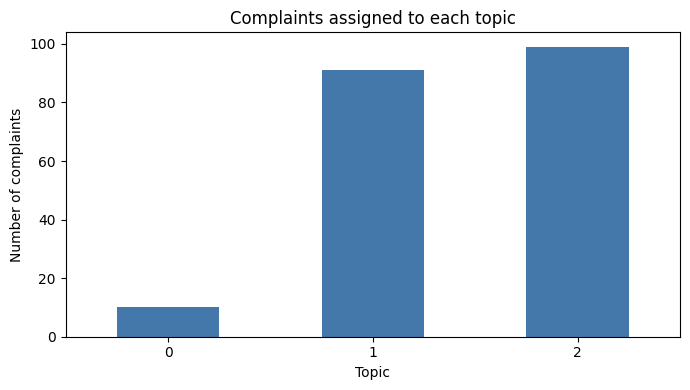

In [ ]:
output = Path('kanak_results')
output.mkdir(exist_ok=True)
topic_sizes = data.groupby('topic').size().rename('complaints').to_frame()
topic_sizes['percent'] = (100 * topic_sizes['complaints'] / len(data)).round(1)
display(topic_sizes)
ax = topic_sizes['complaints'].plot.bar(color='#4477AA', rot=0, figsize=(7, 4))
ax.set(title='Complaints assigned to each topic', xlabel='Topic', ylabel='Number of complaints')
plt.tight_layout()
plt.savefig(output / 'topic_sizes.png', dpi=150)
plt.show()

## 2. How did companies respond?
The first table shows **counts**. The second shows **percentages within each topic**; every row adds to about 100%.

“Closed with explanation” is a response category, not proof that the consumer's problem was resolved. “Non-monetary relief” is a separate response category; do not combine them into a success rate.

Counts


company_response_to_consumer,Closed,Closed with explanation,Closed with non-monetary relief
topic,,,
0,2,4,4
1,4,60,27
2,5,61,33


Percentages within each topic


company_response_to_consumer,Closed,Closed with explanation,Closed with non-monetary relief
topic,,,
0,20.0,40.0,40.0
1,4.4,65.9,29.7
2,5.1,61.6,33.3


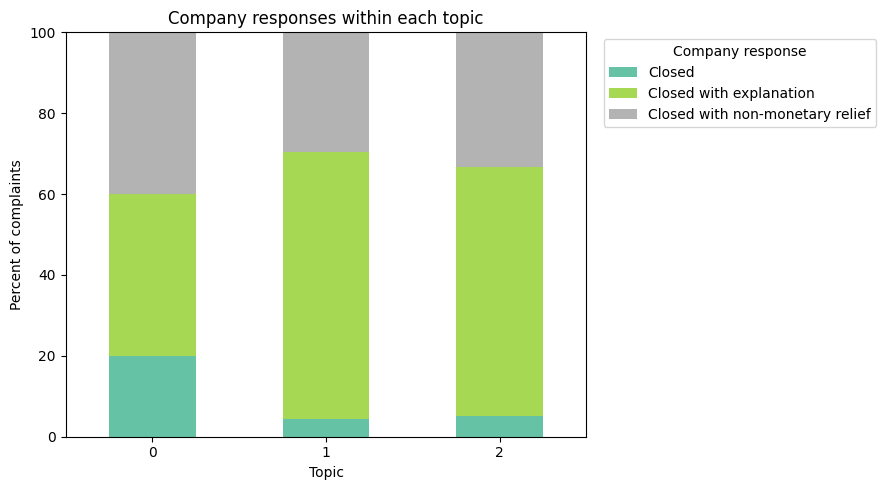

In [ ]:
responses = data['company_response_to_consumer'].astype('string').str.strip()
responses = responses.replace('', pd.NA).fillna('Missing')
response_counts = pd.crosstab(data['topic'], responses)
response_percent = response_counts.div(response_counts.sum(axis=1), axis=0) * 100
print('Counts')
display(response_counts)
print('Percentages within each topic')
display(response_percent.round(1))
ax = response_percent.plot.bar(stacked=True, figsize=(9, 5), rot=0, colormap='Set2')
ax.set(title='Company responses within each topic', xlabel='Topic', ylabel='Percent of complaints', ylim=(0, 100))
ax.legend(title='Company response', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(output / 'company_responses.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. What can we say about consumer disputes?
**Missing means unknown. Never replace missing values with “No”.**
This cell keeps missing values visible and reports coverage. Comparisons based only on recorded answers may be biased if those answers are not representative. A dispute flag also does not directly measure whether the problem was resolved.

In [ ]:
dispute_counts = None
coverage = None
if 'consumer_disputed' in data.columns:
    disputes = data['consumer_disputed'].astype('string').str.strip().replace('', pd.NA)
    recorded = disputes.notna()
    print(f'Dispute values recorded: {recorded.sum()} of {len(data)}')
    dispute_counts = pd.crosstab(data['topic'], disputes.fillna('Missing'))
    display(dispute_counts)
    coverage = recorded.groupby(data['topic']).agg(['sum', 'count'])
    coverage.columns = ['recorded', 'total']
    coverage['recorded_percent'] = (100 * coverage['recorded'] / coverage['total']).round(1)
    display(coverage)
else:
    print('No consumer_disputed column: skip this optional comparison.')

Dispute values recorded: 74 of 200


consumer_disputed,False,Missing,True
topic,,,
0,5,4,1
1,21,61,9
2,30,61,8


,recorded,total,recorded_percent
topic,,,
0,6,10,60.0
1,30,91,33.0
2,38,99,38.4


## 4. Write the conclusion
Edit the text cell below. Use the tables above; do not invent topic names or explanations for differences.

### My project summary
- **Question:** What themes appear in the complaint narratives, and how do company responses vary across the topic groups?
- **Method:** I cleaned the narratives, explored word frequencies and TF-IDF, and used LDA to explore topics. The final exploratory model used three topics after removing recurring company names and numeric tokens.
- **Dataset:** This analysis contains 200 complaints with narratives. My results describe this analyzed subset.
- **Main finding:** The most frequent company response was to close the complaint with an explanation (not provided within the dataset). The second most common company response was to close the complaint without providing any sort of monetary compensation. Topics 2 and 3 had similar company response distributions.
- **Small groups:** Topic 1 contained only 10 complaints, so its percentages need caution.
- **Missing data:** Dispute values were recorded for 74 complaints. However, Topics 2 and 3 had only approximately 1/3 to 2/5 of complaints disputed, which is significant due to how little disputes there are. Missing values were kept separate.
- **Limits:** Topic labels need human review; complaints may contain several themes. The chosen three-topic model is exploratory, not a proven optimum. Differences are descriptive associations, not evidence of causation. Results cannot automatically be generalized to all consumers.
- **Next improvement:** Review more example complaints per topic and compare topic quality across model settings before making stronger claims.

**Scope check:** This companion finishes the narrative-topic analysis. The original plan also mentioned comparing complaints with and without narratives; that comparison requires the original full dataset and is not completed here.

## 5. Save the results
This creates a ZIP with the tables and two charts. Then use **File → Download → Download .ipynb** to save this notebook with its outputs and your edited conclusion.

Your final hand-in: the original analysis notebook, this completed companion, and the results ZIP. The ZIP contains summary results, not the raw complaint narratives.

In [ ]:
import shutil

topic_sizes.to_csv(output / 'topic_sizes.csv')
response_counts.to_csv(output / 'response_counts.csv')
response_percent.round(1).to_csv(output / 'response_percentages.csv')
if dispute_counts is not None:
    dispute_counts.to_csv(output / 'dispute_counts_including_missing.csv')
    coverage.to_csv(output / 'dispute_coverage.csv')
archive = shutil.make_archive('kanak_project_results', 'zip', output)
files.download(archive)
print('Done! Save this notebook too, after filling in your conclusion.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done! Save this notebook too, after filling in your conclusion.
